In [1]:
#Image imports
from pathlib import Path
from PIL import Image
import torch

#MLX-VLM imports
from mlx_vlm import load, generate
from mlx_vlm.prompt_utils import apply_chat_template
from mlx_vlm.generate import stream_generate
from mlx_vlm.utils import prepare_inputs

import matplotlib.pyplot as plt

#Streaming imports
import time
from threading import Thread
from transformers import TextIteratorStreamer

#Schema validation imports
import json
import re
from typing import Literal
from pydantic import BaseModel, Field, ValidationError, field_validator

#Environment imports
from dotenv import load_dotenv
load_dotenv() 

W1023 13:58:22.770000 50508 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


True

In [2]:
img_path = Path("../data/test-penguin.jpeg")
img = Image.open(img_path)

In [3]:
model, processor = load("mlx-community/LocateAnything-3B-4bit")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

In [4]:
prompt = apply_chat_template(
    processor,
    model.config,
    "Detect all penguins in the image.",
    num_images=1,
)

In [5]:
inputs = prepare_inputs(
    processor,
    images=[str(img_path)],
    prompts=prompt,
)
print("INPUT KEYS:", list(inputs.keys()))
for k, v in inputs.items():
    shape = getattr(v, "shape", None)
    dtype = getattr(v, "dtype", type(v).__name__)
    print(f"  {k}: shape={shape} dtype={dtype}")


INPUT KEYS: ['attention_mask', 'input_ids', 'pixel_values', 'image_grid_hws', '_grid_shapes', 'image_token_id']
  attention_mask: shape=(1, 811) dtype=mlx.core.int32
  input_ids: shape=(1, 811) dtype=mlx.core.int32
  pixel_values: shape=(3128, 3, 14, 14) dtype=mlx.core.float32
  image_grid_hws: shape=(1, 2) dtype=mlx.core.int32
  _grid_shapes: shape=None dtype=list
  image_token_id: shape=() dtype=mlx.core.int32


In [12]:
import mlx.core as mx

# rebuild inputs (pbd_generate pops keys, so don't reuse a mutated dict)
inputs = prepare_inputs(
    processor,
    images=[str(img_path)],
    prompts=prompt,
)
print("INPUT KEYS:", list(inputs.keys()))
for k, v in inputs.items():
    shape = getattr(v, "shape", None)
    dtype = getattr(v, "dtype", type(v).__name__)
    print(f"  {k}: shape={shape} dtype={dtype}")

input_ids = inputs.pop("input_ids")
inputs.pop("attention_mask", None)

GENERATION_MODE = "hybrid"  # "fast" | "hybrid" | "slow"
MAX_TOKENS = 256

# warm-up (Metal compile / first-call cost — exclude from timing)
_ = model.pbd_generate(
    input_ids,
    generation_mode=GENERATION_MODE,
    max_tokens=MAX_TOKENS,
    **inputs,
)
mx.eval(_)  # ensure work finished before starting the clock

t0 = time.perf_counter()
token_ids = model.pbd_generate(
    input_ids,
    generation_mode=GENERATION_MODE,
    max_tokens=MAX_TOKENS,
    **inputs,
)
mx.eval(token_ids)
T = time.perf_counter() - t0

# pbd_generate returns a list[int] (or array-like)
if hasattr(token_ids, "tolist"):
    token_ids = token_ids.tolist()
if isinstance(token_ids, list) and token_ids and isinstance(token_ids[0], list):
    token_ids = token_ids[0]  # some builds return [[...]]

tok = processor.tokenizer if hasattr(processor, "tokenizer") else processor
raw = tok.decode(token_ids, skip_special_tokens=False)
print(raw)
print()

N = len(token_ids)
B = raw.count("<box>")
throughput = N / T
boxes_per_sec = B / T if T > 0 else 0.0

print(f"mode = {GENERATION_MODE}")
print(f"N [New tokens] = {N}")
print(f"B [Boxes]      = {B}")
print(f"T [Wall time]  = {T}")
print(f"N/T [Throughput] = {throughput:.2f} tok/s")
print(f"B/T [Boxes/s]    = {boxes_per_sec:.2f} boxes/s")

INPUT KEYS: ['attention_mask', 'input_ids', 'pixel_values', 'image_grid_hws', '_grid_shapes', 'image_token_id']
  attention_mask: shape=(1, 811) dtype=mlx.core.int32
  input_ids: shape=(1, 811) dtype=mlx.core.int32
  pixel_values: shape=(3128, 3, 14, 14) dtype=mlx.core.float32
  image_grid_hws: shape=(1, 2) dtype=mlx.core.int32
  _grid_shapes: shape=None dtype=list
  image_token_id: shape=() dtype=mlx.core.int32
<ref>p</ref><box><74><350><221><619></box><box><98><280><203><435></box><box><241><298><396><605></box><box><273><247><380><391></box><box><291><296><403><541></box><box><386><268><502><376></box><box><405><237><502><359></box><box><414><350><536><612></box><box><453><303><535><547></box><box><478><233><532><477></box><box><515><305><604><550></box><box><538><238><656><356></box><box><569><347><715><630></box><box><574><256><660><507></box><box><655><244><706><491></box><box><701><273><750><511></box><box><716><251><733><331></box><box><731><253><772><331></box><box><733><321><

In [13]:
chunks = []
token_ids = []
t0 = time.perf_counter()
for chunk in stream_generate(
    model,
    processor,
    prompt=prompt,
    image=str(img_path),
    max_tokens=256,
    temperature=0.0,
):
    if chunk is None:
        continue
    text = getattr(chunk, "text", None) or ""
    if text:
        print(text, end="", flush=True)
        chunks.append(text)
    # some mlx-vlm versions expose .token / .tokens
    tok = getattr(chunk, "token", None)
    if tok is not None:
        token_ids.append(int(tok))
    elif getattr(chunk, "tokens", None):
        token_ids.extend(int(t) for t in chunk.tokens)
T = time.perf_counter() - t0
raw = "".join(chunks)
print("\n")

N = len(token_ids)  # preferred: count streamed token ids
# fallback if .token wasn't exposed:
if N == 0:
    tok = processor.tokenizer if hasattr(processor, "tokenizer") else processor
    N = len(tok.encode(raw, add_special_tokens=False))
throughput = N / T  # tok/s
print(f"N [New tokens] = {N}")
print(f"T [Wall time]  = {T}")
print(f"N/T [Throughput] = {throughput:.2f} tok/s")


<ref>penguins</ref><box><72><350><221><619></box><box><98><280><204><436></box><box><240><299><396><605></box><box><272><247><381><391></box><box><291><297><403><542></box><box><386><268><461><479></box><box><403><237><502><375></box><box><414><350><522><613></box><box><453><303><535><548></box><box><478><233><532><477></box><box><515><305><604><551></box><box><538><239><592><367></box><box><569><347><716><630></box><box><574><256><657><508></box><box><655><245><706><492></box><box><701><274><750><512></box><box><716><250><733><319></box><box><731><253><772><331></box><box><732><321><854><584></box><box><769><255><828><480></box><box><835><309><993><622></box><box><858><276><997><542></box><box><871><233><978><394></box>

N [New tokens] = 143
T [Wall time]  = 5.789225582993822
N/T [Throughput] = 24.70 tok/s


In [7]:
# --- decode LocateAnything format ---
# e.g. <ref>penguin</ref><box><71><348><221><619></box><box>...
BOX_RE = re.compile(r"<box><(\d+)><(\d+)><(\d+)><(\d+)></box>")
REF_RE = re.compile(r"<ref>(.*?)</ref>", re.S)
def parse_locateanything(text: str) -> list[dict]:
    label = "penguin"
    m = REF_RE.search(text)
    if m:
        # model may echo a long ref; keep it short for plotting
        label = re.sub(r"\s+", " ", m.group(1)).strip()[:40] or "penguin"
    dets = []
    for x1, y1, x2, y2 in BOX_RE.findall(text):
        x1, y1, x2, y2 = map(int, (x1, y1, x2, y2))
        if not (0 <= x1 < x2 <= 1000 and 0 <= y1 < y2 <= 1000):
            continue
        dets.append(
            {
                "bbox_2d": [x1, y1, x2, y2],
                "label": "penguin",
                "ref": label,
            }
        )
    return dets

In [8]:
dets = parse_locateanything(raw)
print(f"decoded {len(dets)} boxes")
print(dets[:3], "..." if len(dets) > 3 else "")

decoded 23 boxes
[{'bbox_2d': [72, 350, 221, 619], 'label': 'penguin', 'ref': 'penguins'}, {'bbox_2d': [98, 280, 204, 436], 'label': 'penguin', 'ref': 'penguins'}, {'bbox_2d': [240, 299, 396, 605], 'label': 'penguin', 'ref': 'penguins'}] ...


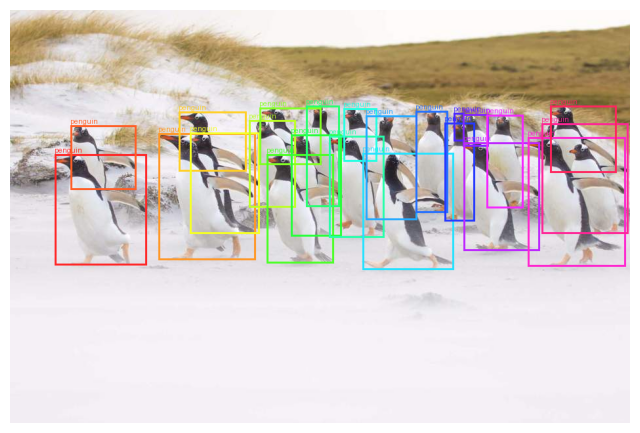

In [10]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import colorsys

def norm1000_to_pixels(bbox, w, h):
    x1, y1, x2, y2 = bbox
    return [
        int(x1 / 1000 * w),
        int(y1 / 1000 * h),
        int(x2 / 1000 * w),
        int(y2 / 1000 * h),
    ]

def instance_colors(n: int):
    """Distinct RGB colors for n instances."""
    cols = []
    for i in range(n):
        h = i / max(n, 1)
        r, g, b = colorsys.hsv_to_rgb(h, 0.85, 1.0)
        cols.append(tuple(int(255 * c) for c in (r, g, b)))
    return cols

img = Image.open("../data/test-penguin.jpeg").convert("RGB")
w, h = img.size
vis = img.copy()
draw = ImageDraw.Draw(vis)
colors = instance_colors(len(dets))

#instance detection
for i, d in enumerate(dets):
    x1, y1, x2, y2 = norm1000_to_pixels(d["bbox_2d"], w, h)
    color = colors[i]
    draw.rectangle([x1, y1, x2, y2], outline=color, width=3)
    sub = d.get("sub_label") or ""
    label = d["label"] if not sub else f'{d["label"]}: {sub}'
    draw.text((x1, max(0, y1 - 12)), label, fill=color)

plt.figure(figsize=(8, 8))
plt.imshow(vis)
plt.axis("off")
plt.show()